# Análisis de Componentes Principales (PCA)

**Fuente:** https://www.geeksforgeeks.org/data-analysis/principal-component-analysis-pca/

**Modificador y Ejecutor:** Carlos Francisco Montoya Urzua

---

El **PCA** (*Principal Component Analysis* — Análisis de Componentes Principales) es una técnica de reducción de dimensionalidad que nos ayuda a reducir el número de características en un conjunto de datos conservando la información más importante. Transforma conjuntos de datos complejos convirtiendo características correlacionadas en un conjunto más pequeño de componentes no correlacionados.

Nos ayuda a eliminar la redundancia, mejorar la eficiencia computacional y hacer que los datos sean más fáciles de visualizar y analizar.

## Cómo Funciona el Análisis de Componentes Principales

El PCA utiliza álgebra lineal para transformar los datos en nuevas características llamadas **componentes principales**. Las encuentra calculando los vectores propios (*eigenvectors* — direcciones) y valores propios (*eigenvalues* — importancia) a partir de la matriz de covarianza. El PCA selecciona los componentes principales con los valores propios más altos y proyecta los datos sobre ellos para simplificar el conjunto de datos.

> **Nota:** Prioriza las direcciones donde los datos varían más, porque mayor variación = información más útil.

Imagina que observas una nube de puntos de datos desordenada —como estrellas en el cielo— y quieres simplificarla. El PCA te ayuda a encontrar los "ángulos más importantes" para ver esta nube y no perder los patrones grandes. A continuación, explicamos cómo funciona paso a paso.

### Paso 1: Estandarizar los Datos

Las distintas características pueden tener diferentes unidades y escalas, como el salario frente a la edad. Para compararlas de forma justa, el PCA primero **estandariza** los datos haciendo que cada característica tenga:

- Una media de **0**
- Una desviación estándar de **1**

$$Z = \frac{X - \mu}{\sigma}$$

donde:
- $\mu$ es la media de las características independientes: $\mu = \{\mu_1, \mu_2, \cdots, \mu_m\}$
- $\sigma$ es la desviación estándar de las características independientes: $\sigma = \{\sigma_1, \sigma_2, \cdots, \sigma_m\}$

### Paso 2: Calcular la Matriz de Covarianza

A continuación, el PCA calcula la **matriz de covarianza** para ver cómo se relacionan las características entre sí —si aumentan o disminuyen juntas—. La covarianza entre dos características $x_1$ y $x_2$ es:

$$\text{cov}(x_1, x_2) = \frac{\sum_{i=1}^{n}(x1_i - \bar{x_1})(x2_i - \bar{x_2})}{n-1}$$

donde:
- $\bar{x}_1$ y $\bar{x}_2$ son los valores medios de las características $x_1$ y $x_2$
- $n$ es el número de puntos de datos

El valor de la covarianza puede ser positivo, negativo o cero.

### Paso 3: Encontrar los Componentes Principales

El PCA identifica nuevos ejes donde los datos se dispersan más:

- **1er Componente Principal (PC1):** La dirección de máxima varianza (mayor dispersión).
- **2do Componente Principal (PC2):** La siguiente mejor dirección, **perpendicular a PC1**, y así sucesivamente.

Estas direcciones provienen de los vectores propios (*eigenvectors*) de la matriz de covarianza, y su importancia se mide con los valores propios (*eigenvalues*). Para una matriz cuadrada **A**, un vector propio **X** (un vector no nulo) y su valor propio correspondiente $\lambda$ satisfacen:

$$AX = \lambda X$$

Esto significa:
- Cuando **A** actúa sobre **X**, solo estira o contrae **X** por el escalar $\lambda$.
- La dirección de **X** permanece sin cambios; por lo tanto, los vectores propios definen las "direcciones estables" de **A**.

Los valores propios ayudan a ordenar estas direcciones por importancia.

### Paso 4: Seleccionar las Mejores Direcciones y Transformar los Datos

Después de calcular los valores propios y los vectores propios, el PCA los ordena según la cantidad de información que capturan. Luego:

1. Se seleccionan los **k componentes principales** que capturan la mayor parte de la varianza (por ejemplo, el 95%).
2. Se transforma el conjunto de datos original proyectándolo sobre estos componentes principales.

Esto significa que reducimos el número de características (dimensiones) conservando los patrones importantes de los datos.

En el conjunto de datos original, las dos características "Radio" y "Área" se representan por los ejes negros. El PCA identifica dos nuevas direcciones: **PC₁** y **PC₂**, que son los componentes principales.

- Estos nuevos ejes son versiones rotadas de los originales. **PC₁** captura la máxima varianza en los datos, es decir, contiene la mayor información, mientras que **PC₂** captura la varianza restante y es perpendicular a **PC₁**.
- La dispersión de datos es mucho mayor a lo largo de **PC₁** que a lo largo de **PC₂**. Por eso se elige **PC₁** para la reducción de dimensionalidad. Al proyectar los puntos de datos sobre **PC₁**, transformamos eficazmente los datos 2D a 1D conservando la mayor parte de la estructura e información importante.

## Implementación del Análisis de Componentes Principales en Python

El PCA utiliza una transformación lineal basada en preservar la mayor varianza en los datos usando el menor número de dimensiones. Incluye los siguientes pasos:

---

### Paso 1: Importar las Librerías Necesarias

Importamos las librerías necesarias: `pandas`, `numpy`, `scikit-learn`, `seaborn` y `matplotlib` para visualizar los resultados.

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

### Paso 2: Crear el Conjunto de Datos de Muestra

Creamos un pequeño conjunto de datos con tres características: Altura (*Height*), Peso (*Weight*), Edad (*Age*) y Género (*Gender*).

In [7]:
data = {
    'Height': [170, 165, 180, 175, 160, 172, 168, 177, 162, 158],
    'Weight': [65, 59, 75, 68, 55, 70, 62, 74, 58, 54],
    'Age':    [30, 25, 35, 28, 22, 32, 27, 33, 24, 21],
    'Gender': [1, 0, 1, 1, 0, 1, 0, 1, 0, 0],  # 1 = Masculino, 0 = Femenino
    'IQ':     [100, 120,90,100, 110, 125, 130, 90, 90, 100]#ATRIBUTO AGREGADO
}
df = pd.DataFrame(data)
print(df)

   Height  Weight  Age  Gender   IQ
0     170      65   30       1  100
1     165      59   25       0  120
2     180      75   35       1   90
3     175      68   28       1  100
4     160      55   22       0  110
5     172      70   32       1  125
6     168      62   27       0  130
7     177      74   33       1   90
8     162      58   24       0   90
9     158      54   21       0  100


**Salida:** Se muestra el DataFrame con 10 filas y 4 columnas (Altura, Peso, Edad y Género).

---

### Paso 3: Estandarizar los Datos

Dado que las características tienen escalas diferentes —Altura frente a Edad—, estandarizamos los datos. Esto hace que todas las características tengan media = 0 y desviación estándar = 1, de modo que ninguna característica domine simplemente por sus unidades.

In [8]:
X = df.drop('Gender', axis=1)
y = df['Gender']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Paso 4: Aplicar el Algoritmo PCA

- Reducimos los datos de 3 características a 2 nuevas características llamadas componentes principales. Estos componentes capturan la mayor parte de la información original pero en menos dimensiones.
- Dividimos los datos en 70% entrenamiento y 30% prueba.
- Entrenamos un modelo de **regresión logística** sobre los datos de entrenamiento reducidos y predecimos las etiquetas de género en el conjunto de prueba.

In [9]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.3, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

### Paso 5: Evaluar con la Matriz de Confusión

La **matriz de confusión** compara las etiquetas reales frente a las predichas. Esto facilita ver dónde las predicciones fueron correctas o incorrectas.

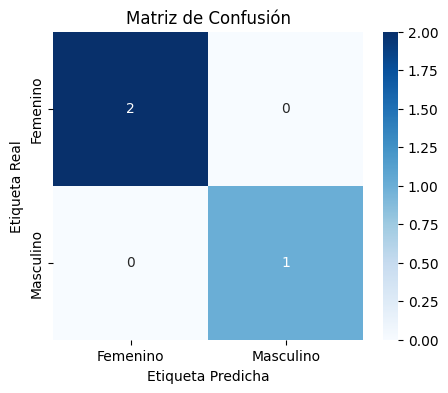

In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Femenino', 'Masculino'],
            yticklabels=['Femenino', 'Masculino'])
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Real')
plt.title('Matriz de Confusión')
plt.show()

**Salida:** El mapa de calor muestra la matriz de confusión comparando las predicciones del modelo con las etiquetas reales de género.

---

### Paso 6: Visualizar el Resultado del PCA

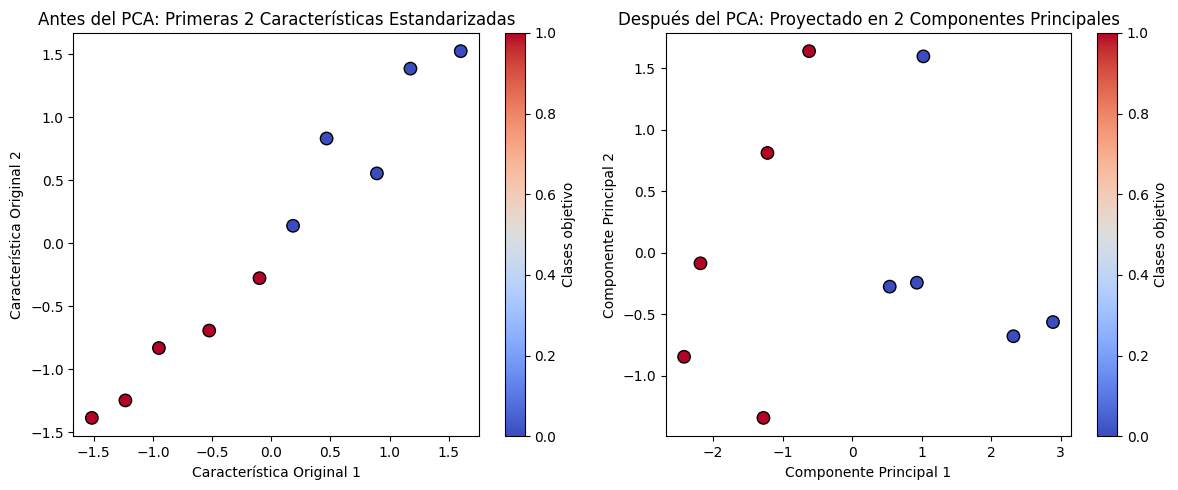

In [11]:
y_numeric = pd.factorize(y)[0]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_numeric,
            cmap='coolwarm', edgecolor='k', s=80)
plt.xlabel('Característica Original 1')
plt.ylabel('Característica Original 2')
plt.title('Antes del PCA: Primeras 2 Características Estandarizadas')
plt.colorbar(label='Clases objetivo')

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_numeric,
            cmap='coolwarm', edgecolor='k', s=80)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Después del PCA: Proyectado en 2 Componentes Principales')
plt.colorbar(label='Clases objetivo')

plt.tight_layout()
plt.show()

**Salida:**

- **Gráfico izquierdo — Antes del PCA:** Muestra los **datos originales estandarizados** graficados usando las dos primeras características. No hay garantía de una separación clara entre clases, ya que son dimensiones de entrada sin procesar.

- **Gráfico derecho — Después del PCA:** Muestra los **datos transformados** usando los **2 componentes principales**. Estos nuevos componentes capturan la **máxima varianza**, lo que generalmente muestra una mejor **separación entre clases y estructura**, facilitando el análisis y el modelado.

## Ventajas del Análisis de Componentes Principales

1. **Manejo de la Multicolinealidad:** Crea nuevas variables no correlacionadas para abordar los problemas cuando las características originales están altamente correlacionadas.
2. **Reducción del Ruido:** Elimina los componentes con baja varianza, mejorando la claridad de los datos.
3. **Compresión de Datos:** Representa los datos con menos componentes, reduciendo las necesidades de almacenamiento y acelerando el procesamiento.
4. **Detección de Valores Atípicos:** Identifica puntos de datos inusuales al mostrar cuáles se desvían significativamente en el espacio reducido.

---

## Desventajas del Análisis de Componentes Principales

1. **Dificultad de Interpretación:** Los nuevos componentes son combinaciones de las variables originales, lo que puede ser difícil de explicar.
2. **Sensibilidad al Escalado de Datos:** Requiere un escalado adecuado de los datos antes de su aplicación; de lo contrario, los resultados pueden ser engañosos.
3. **Pérdida de Información:** Reducir las dimensiones puede perder información importante si se conservan muy pocos componentes.
4. **Suposición de Linealidad:** Funciona mejor cuando las relaciones entre variables son lineales y puede tener dificultades con datos no lineales.
5. **Complejidad Computacional:** Puede ser lento y consumir muchos recursos en conjuntos de datos muy grandes.
6. **Riesgo de Sobreajuste:** Usar demasiados componentes o trabajar con un conjunto de datos pequeño podría producir modelos que no generalizan bien.